# 01_3 Synthetic WSI embeddings from the PCA-reduced tile vectors (clusters + Gaussians)

**Overview.** This notebook generates synthetic whole-slide-image (WSI) bags from the PCA-reduced UNI2-h tile embeddings saved by `01_2_vectors_to_pca_analysis.ipynb`. For every diagnostic class, the Training tiles are partitioned into *k* clusters (MiniBatchKMeans, Sculley 2010); every cluster is described by a multivariate Gaussian, $x \sim \mathcal{N}(\mu_c, \Sigma_c + \lambda I)$, and a synthetic bag is assembled from a random blend of `N_TEMPLATES_PER_WSI` real Training slides of the same class (Dirichlet weights), whose tile counts and cluster proportions are combined as weighted means. In this way the variation in slide size and in cluster composition of the real data is kept, without using a single global average, without copying a real embedding and without any bag following the composition of one slide. This reduces the link between a synthetic bag and a single real slide; it is not a formal privacy guarantee and no privacy evaluation is made here.

Only the official **Training** slides are used for every estimated quantity: the clusters, the Gaussian parameters, and the templates. The PCA of 01_2 was itself fitted on Training tiles only. Validation and Testing slides are never opened; a mismatch between the slide table, the files and the PCA metadata stops the run. The original PCA files are only read. The notebook does not train a classifier and computes no classification metric; the diagnostics only verify that the generator behaves as specified.

The generation step is behind a small interface (`GeneratorBase`); only the Gaussian method is implemented. Synthetic bags are written to `SYNTHETIC_OUTPUT_DIR/<method>/pca_<D>/k_<K>/` with the keys of the PCA files, together with `metadata.json`, `cluster_models.pt` and `labels.csv`; the label sheet of all configurations is `labels/BRACS_synthetic.csv`. No figure or report is exported.

```mermaid
flowchart TD
    PCA[("pca_D/UNI2-h/<br/>one .pt file per slide (from 01_2)")] --> SEL["3. build_slide_table + load_training_slides<br/>Training slides only, validated"]
    SEL --> SAMP["4. sample_class_tiles<br/>slide-balanced, per class"]
    SAMP --> KM["4. fit_class_clusters<br/>MiniBatchKMeans per class and k"]
    KM --> STAT["5. collect_class_statistics<br/>one streaming pass: composition + Gaussian sums"]
    STAT --> COMP["5. composition_table<br/>real WSI templates (blended in 7)"]
    STAT --> GAUSS["6. GaussianGenerator.fit<br/>mean, variance / covariance, lambda"]
    COMP --> GEN["7. generate_configuration<br/>make_synthetic_wsi"]
    GAUSS --> GEN
    GEN --> DIAG["8. diagnostics<br/>tables and plots"]
    GEN --> SAVE["9. metadata, labels, validation"]
    SAVE --> OUT[("synthetic/method/pca_D/k_K/<br/>SYN_*.pt, metadata.json, labels.csv")]
    SAVE --> LAB[("labels/BRACS_synthetic.csv")]
```

## 1. Setup

The environment is recorded so the run can be reproduced.

In [1]:
# STEP 1: Standard-library imports and general-purpose third-party libraries
import sys
import matplotlib
import numpy as np
import pandas as pd
import scipy
import sklearn
import torch

# STEP 2: Print library versions for reproducibility
print('System Version:', sys.version)
print('PyTorch version:', torch.__version__)
print('Numpy version:', np.__version__)
print('Pandas version:', pd.__version__)
print('SciPy version:', scipy.__version__)
print('scikit-learn version:', sklearn.__version__)
print('Matplotlib version:', matplotlib.__version__)

System Version: 3.14.7 (main, Aug 10 2026, 07:46:56) [GCC 16.1.1 20260728]
PyTorch version: 2.15.0+cu132
Numpy version: 2.5.4
Pandas version: 3.1.1
SciPy version: 1.18.1
scikit-learn version: 1.9.1
Matplotlib version: 3.11.2


The project's own building blocks are imported.

In [2]:
# STEP 1: Standard-library imports
from pathlib import Path

# STEP 2: Import this project's own building blocks
from utils.dataset_overview import build_slide_table
from utils.mil_train import set_seed
from utils.pca_analysis import timed
from utils.synthetic_gaussian import (build_generator, cluster_size_table, collect_class_statistics, composition_comparison,
                                      composition_table, fit_class_clusters, generate_configuration, generation_check,
                                      load_training_slides, plot_cluster_sizes, plot_composition, plot_distribution_stats,
                                      plot_pc_scatter, plot_tile_counts, sample_class_tiles, save_configuration_metadata,
                                      training_overview, write_synthetic_labels)

## 2. Constants

Every setting is defined here and any combination of `PCA_DIMENSIONS` and `K_VALUES` can be run without changing the implementation; the dimensions must exist as `pca_<D>/` folders under `PCA_INPUT_DIR`. `GENERATION_METHOD` selects the generator (`'gaussian'` only). Each class is clustered separately on a slide-balanced sample of its Training tiles: every slide gives at most `MAX_TILES_PER_WSI_FIT` tiles and at most `MAX_TILES_PER_CLASS` tiles are used per class (the quotas are reduced equally when the total is larger, so large slides do not dominate). MiniBatchKMeans uses `KMEANS_BATCH_SIZE` and `KMEANS_N_INIT` initialisations; the sample of a class is reused for every *k*.

The Gaussian of a cluster has a diagonal covariance by default (`COVARIANCE_TYPE = 'diag'`: $\mathrm{diag}(\Sigma_c) + \lambda$ with $\lambda$ = `COVARIANCE_REG`); `'full'` uses the Cholesky factor of $\Sigma_c + \lambda I$ and needs $O(kD^2)$ memory per class. A cluster with fewer than `MIN_CLUSTER_TILES` Training tiles has no reliable covariance estimate and uses the pooled within-cluster variance of its class. `N_TEMPLATES_PER_WSI` real Training slides are blended in each bag with Dirichlet weights of concentration `TEMPLATE_CONCENTRATION` (a small concentration lets one template dominate; `1` makes the weights uniform on the simplex; `N_TEMPLATES_PER_WSI = 1` reproduces a single-slide template). `MAX_SYNTHETIC_TILES` caps the size of a synthetic bag (`None` = the weighted mean size of its templates). `N_SYNTHETIC_WSIS_PER_CLASS` bags are generated per class and configuration. `DIAGNOSTIC_CONFIG` is the (dimension, *k*) pair shown in the detailed plots of section 8. `SAVE_SYNTHETIC_EMBEDDINGS` turns the storage on; existing synthetic files are not replaced unless `OVERWRITE` is set. The input spelling `phd_streamembed_features` follows the other notebooks.

In [3]:
# Major variables
PCA_DIMENSIONS = [256, 512]                                        # STEP 1: PCA dimensions to run (folders pca_<D>)
K_VALUES = [5, 10, 25, 50]                                              # STEP 2: Clusters per class
GENERATION_METHOD = 'gaussian'                                          # STEP 3: Generator (only 'gaussian' exists)
N_SYNTHETIC_WSIS_PER_CLASS = 100                                        # STEP 4: Synthetic WSIs per class and configuration
RANDOM_SEED = 42                                                        # STEP 5: Seed of every random choice
PCA_INPUT_DIR = Path('/mnt/Scratch/phd_streamembed_features')           # STEP 6: Holds pca_<D>/<MODEL_NAME>/<slide>.pt (from 01_2)
SYNTHETIC_OUTPUT_DIR = Path('/mnt/Scratch/phd_streamembed_features/synthetic')   # STEP 7: Receives <method>/pca_<D>/k_<K>/
SAVE_SYNTHETIC_EMBEDDINGS = True                                        # STEP 8: Store the synthetic bags (sections 7 and 9)
MODEL_NAME = 'UNI2-h'                                                   # STEP 9: Subfolder with the per-slide files
LABELS_FILE = Path('labels/BRACS.xlsx')                                 # STEP 10: Slide labels, patients and official split
LABELS_SYNTHETIC_FILE = Path('labels/BRACS_synthetic.csv')              # STEP 11: Label sheet of the synthetic WSIs
MAX_TILES_PER_WSI_FIT, MAX_TILES_PER_CLASS = 500, 50_000                # STEP 12: Tiles per slide and per class used to fit the clusters
KMEANS_BATCH_SIZE, KMEANS_N_INIT = 4096, 3                              # STEP 13: MiniBatchKMeans batch size and initialisations
COVARIANCE_TYPE, COVARIANCE_REG = 'diag', 1e-3                          # STEP 14: 'diag' or 'full'; lambda added to the variances
MIN_CLUSTER_TILES = 10                                                  # STEP 15: Smaller clusters use the pooled class variance
MAX_SYNTHETIC_TILES = None                                              # STEP 16: Cap on tiles per synthetic WSI (None = blended template size)
N_TEMPLATES_PER_WSI, TEMPLATE_CONCENTRATION = 5, 1.0                    # STEP 17: Real slides blended per bag (1 = one slide); Dirichlet concentration of the weights
DIAGNOSTIC_CONFIG = (PCA_DIMENSIONS[0], K_VALUES[-1])                   # STEP 18: (dimension, k) of the detailed plots
OVERWRITE = False                                                       # STEP 19: Replace existing synthetic outputs (default: refuse)
set_seed(RANDOM_SEED)
assert DIAGNOSTIC_CONFIG[0] in PCA_DIMENSIONS and DIAGNOSTIC_CONFIG[1] in K_VALUES

## 3. Training-data selection

The slide table gives the class, patient and official set of each slide. Only the **Training** slides are selected. For every dimension, each Training slide must have a file with the expected number of columns, finite values, the label of the table and the stored set `Training`; the `fit_slides` recorded by 01_2 must be Training slides too. Any violation raises an error instead of silently using more slides. The table reports the Training slides, patients and tiles per class.

In [4]:
# STEP 1: Slide table and the official Training slides
table = build_slide_table(LABELS_FILE)

# STEP 2: Validate the Training files of every dimension (memory-mapped, no tile is loaded)
training = {}
with timed('training-data selection'):
    for dim in PCA_DIMENSIONS:
        training[dim] = load_training_slides(table, PCA_INPUT_DIR / f'pca_{dim}', MODEL_NAME, dim)
classes = training[PCA_DIMENSIONS[0]]['classes']
train = training[PCA_DIMENSIONS[0]]['train']
assert all(training[d]['train'][['slide', 'n_tiles']].equals(train[['slide', 'n_tiles']]) for d in PCA_DIMENSIONS)   # same slides and tile counts in every dimension

# STEP 3: Training WSIs and tiles per class
display(training_overview(train, classes))

[training-data selection] 0.2 s


,label,wsis,patients,tiles,median_tiles,min_tiles,max_tiles
0,N,27,18,139115,2939.0,26,19418
1,PB,120,66,1471945,10868.5,337,28956
2,UDH,56,34,560306,8328.0,628,35287
3,FEA,24,14,348670,12894.0,4700,30962
4,ADH,28,16,291515,10492.5,1712,17035
5,DCIS,40,21,468547,10977.5,2083,26726
6,IC,100,53,1111056,10514.5,875,26885


## 4. Class-specific MiniBatchKMeans

For each dimension and class, a slide-balanced sample of Training tiles is drawn once and a MiniBatchKMeans is fitted for every *k* (classes are never combined). A seed is derived from the global seed, the dimension, *k* and the class, so each fit is reproducible and independent of the order of the loops. If a class sample has fewer than *k* tiles, *k* is reduced for that class and recorded.

In [5]:
# STEP 1: Sample once per (dimension, class); fit one MiniBatchKMeans per k
samples, clusters, real_diag = {}, {}, {}
for dim in PCA_DIMENSIONS:
    pca_dir = PCA_INPUT_DIR / f'pca_{dim}'
    for ci, label in enumerate(classes):
        with timed(f'D={dim} {label}: sample + fit k={K_VALUES}'):
            X = sample_class_tiles(pca_dir, MODEL_NAME, train, label, MAX_TILES_PER_WSI_FIT, MAX_TILES_PER_CLASS, RANDOM_SEED + dim + ci)
            rng = np.random.default_rng([RANDOM_SEED, dim, ci])
            real_diag[(dim, label)] = X[rng.choice(len(X), min(len(X), 5000), replace=False)]   # STEP 2: small real reference for the diagnostics
            for k in K_VALUES:
                seed = int(np.random.default_rng([RANDOM_SEED, dim, k, ci]).integers(2**31 - 1))
                clusters.setdefault((dim, k), {})[label] = fit_class_clusters(X, k, KMEANS_BATCH_SIZE, seed, KMEANS_N_INIT)
        del X
print({key: {c: m.n_clusters for c, m in per.items()} for key, per in list(clusters.items())[:1]})

[D=256 N: sample + fit k=[5, 10, 25, 50]] 1.0 s
[D=256 PB: sample + fit k=[5, 10, 25, 50]] 1.4 s
[D=256 UDH: sample + fit k=[5, 10, 25, 50]] 1.1 s
[D=256 FEA: sample + fit k=[5, 10, 25, 50]] 0.8 s
[D=256 ADH: sample + fit k=[5, 10, 25, 50]] 1.2 s
[D=256 DCIS: sample + fit k=[5, 10, 25, 50]] 1.1 s
[D=256 IC: sample + fit k=[5, 10, 25, 50]] 1.4 s
[D=512 N: sample + fit k=[5, 10, 25, 50]] 1.9 s
[D=512 PB: sample + fit k=[5, 10, 25, 50]] 3.4 s
[D=512 UDH: sample + fit k=[5, 10, 25, 50]] 2.2 s
[D=512 FEA: sample + fit k=[5, 10, 25, 50]] 1.9 s
[D=512 ADH: sample + fit k=[5, 10, 25, 50]] 2.0 s
[D=512 DCIS: sample + fit k=[5, 10, 25, 50]] 1.9 s
[D=512 IC: sample + fit k=[5, 10, 25, 50]] 2.5 s
{(256, 5): {'N': 5, 'PB': 5, 'UDH': 5, 'FEA': 5, 'ADH': 5, 'DCIS': 5, 'IC': 5}}


## 5. WSI cluster composition and Gaussian statistics

Every Training slide is read once and its tiles are assigned to the nearest centre of its class. This gives, per slide, the total number of tiles, the tiles per cluster and the normalised cluster proportions, which are the **templates** of the generator. The same pass accumulates per cluster the count, sum and sum of squares (and cross-products for a full covariance) in float64, so the Gaussian parameters use *all* Training tiles of the class, not only the clustering sample. The mean is $\mu_c = \bar{x}_c$ and the covariance is the unbiased sample covariance $\Sigma_c$.

In [6]:
# STEP 1: One streaming pass per (dimension, k, class): composition and sums
stats, compositions = {}, {}
for dim in PCA_DIMENSIONS:
    pca_dir = PCA_INPUT_DIR / f'pca_{dim}'
    for k in K_VALUES:
        with timed(f'D={dim} k={k}: composition and statistics'):
            for label in classes:
                slides = train.loc[train['label'] == label, 'slide'].tolist()
                st = collect_class_statistics(clusters[(dim, k)][label], pca_dir, MODEL_NAME, slides, COVARIANCE_TYPE == 'full')
                stats.setdefault((dim, k), {})[label] = st
                compositions.setdefault((dim, k), {})[label] = composition_table(st, slides)

# STEP 2: Cluster sizes of every configuration, and the check that every Training tile was assigned
sizes = {key: {c: s['n'] for c, s in per.items()} for key, per in stats.items()}
for (dim, k), per in stats.items():
    for label, s in per.items():
        assert s['n'].sum() == training[dim]['train'].query('label == @label')['n_tiles'].sum()
display(compositions[DIAGNOSTIC_CONFIG][classes[-1]].head())

[D=256 k=5: composition and statistics] 3.4 s
[D=256 k=10: composition and statistics] 3.3 s
[D=256 k=25: composition and statistics] 3.3 s
[D=256 k=50: composition and statistics] 3.2 s
[D=512 k=5: composition and statistics] 6.1 s
[D=512 k=10: composition and statistics] 5.9 s
[D=512 k=25: composition and statistics] 5.7 s
[D=512 k=50: composition and statistics] 5.7 s


,slide,n_tiles,prop_0,prop_1,prop_2,prop_3,prop_4,prop_5,prop_6,prop_7,...,prop_40,prop_41,prop_42,prop_43,prop_44,prop_45,prop_46,prop_47,prop_48,prop_49
0,BRACS_280,15070,0.013802,0.012077,0.0,0.004114,0.012541,0.335103,0.010020,0.000000,...,0.014599,0.012342,0.002721,0.000000,0.025547,0.000000,0.000000,0.0,0.000000,0.0
1,BRACS_281,13293,0.049349,0.000301,0.0,0.007222,0.005040,0.021891,0.003460,0.006620,...,0.006620,0.184007,0.000000,0.004438,0.010005,0.000602,0.055819,0.0,0.000301,0.0
2,BRACS_283,14499,0.001379,0.001448,0.0,0.002207,0.008621,0.007587,0.016829,0.000000,...,0.000000,0.202980,0.008552,0.000000,0.104559,0.000621,0.000000,0.0,0.000000,0.0
3,BRACS_288,8847,0.043178,0.064429,0.0,0.052108,0.010625,0.000791,0.007121,0.000226,...,0.013564,0.130214,0.000113,0.000452,0.014468,0.000000,0.032893,0.0,0.021702,0.0
4,BRACS_291,8570,0.112719,0.000817,0.0,0.008868,0.006651,0.009218,0.002800,0.000000,...,0.009802,0.226021,0.031389,0.000117,0.021937,0.027538,0.000000,0.0,0.000000,0.0


## 6. Gaussian parameter estimation

For each class and cluster the generator stores $\mu_c$ and either the variances or the Cholesky factor of $\Sigma_c + \lambda I$. With a diagonal covariance no $D \times D$ matrix is formed. Clusters below `MIN_CLUSTER_TILES` use the pooled within-cluster variance of their class; if a Cholesky factorisation fails, jitter is added until it succeeds. The table lists the fallback clusters and the range of the per-coordinate standard deviation.

In [7]:
# STEP 1: Fit one generator per (dimension, k, class); release the large accumulators afterwards
generators = {}
with timed('Gaussian parameters'):
    for key, per in stats.items():
        for label, st in per.items():
            g = build_generator(GENERATION_METHOD, covariance=COVARIANCE_TYPE, reg=COVARIANCE_REG, min_tiles=MIN_CLUSTER_TILES)
            generators.setdefault(key, {})[label] = g.fit(st, clusters[key][label].cluster_centers_)
            st['xtx'] = None

# STEP 2: Summary
rows = []
for (dim, k), per in generators.items():
    for label, g in per.items():
        sd = np.sqrt(g.var + g.reg)
        rows.append({'pca_dim': dim, 'k': k, 'label': label, 'clusters': len(g.mean), 'fallback_clusters': int(g.small.sum()),
                     'min_sd': sd.min(), 'median_sd': float(np.median(sd)), 'max_sd': sd.max()})
gauss_summary = pd.DataFrame(rows)
display(gauss_summary[(gauss_summary['pca_dim'] == DIAGNOSTIC_CONFIG[0]) & (gauss_summary['k'] == DIAGNOSTIC_CONFIG[1])].round(3))
print('Clusters using the pooled variance, all configurations:', int(gauss_summary['fallback_clusters'].sum()))

[Gaussian parameters] 0.0 s


,pca_dim,k,label,clusters,fallback_clusters,min_sd,median_sd,max_sd
21,256,50,N,50,0,0.207,0.470,2.525
22,256,50,PB,50,0,0.237,0.489,2.913
23,256,50,UDH,50,0,0.233,0.490,2.692
24,256,50,FEA,50,0,0.253,0.490,3.036
25,256,50,ADH,50,0,0.211,0.491,2.408
26,256,50,DCIS,50,0,0.237,0.494,3.163
27,256,50,IC,50,0,0.270,0.515,3.012


Clusters using the pooled variance, all configurations: 0


## 7. Synthetic WSI generation

For each class, `N_SYNTHETIC_WSIS_PER_CLASS` bags are generated. `N_TEMPLATES_PER_WSI` distinct real Training slides of the class are drawn (different bags may reuse a slide) and combined with Dirichlet weights; the weighted mean of their tile counts (capped by `MAX_SYNTHETIC_TILES`) is split over the clusters with the weighted mean of their proportions (largest-remainder rounding, so the counts sum to the tile count). No template identifier is stored; only the number of templates and the largest weight of a single template are recorded, the vectors of each cluster are sampled from its Gaussian in batches, and the tiles are shuffled. Every bag is validated (shape, NaN, infinity) and re-assigned to the class clusters. When `SAVE_SYNTHETIC_EMBEDDINGS` is set, each bag is written as soon as it is generated to `SYNTHETIC_OUTPUT_DIR/<method>/pca_<D>/k_<K>/`, so the bags are never held in memory together. The identifiers (`SYN_<method>_pca<D>_k<K>_<class>_<i>`) contain no real slide or patient identifier.

In [8]:
# STEP 1: Generate every configuration
results = {}
out_dir = SYNTHETIC_OUTPUT_DIR if SAVE_SYNTHETIC_EMBEDDINGS else None
for dim in PCA_DIMENSIONS:
    for k in K_VALUES:
        settings = {'method': GENERATION_METHOD, 'dim': dim, 'k': k, 'seed': RANDOM_SEED, 'n_per_class': N_SYNTHETIC_WSIS_PER_CLASS,
                    'max_tiles': MAX_SYNTHETIC_TILES, 'n_templates': N_TEMPLATES_PER_WSI, 'template_concentration': TEMPLATE_CONCENTRATION, 'model_name': MODEL_NAME, 'pca_dir': PCA_INPUT_DIR / f'pca_{dim}',
                    'save_embeddings': SAVE_SYNTHETIC_EMBEDDINGS, 'covariance': COVARIANCE_TYPE, 'covariance_reg': COVARIANCE_REG,
                    'min_cluster_tiles': MIN_CLUSTER_TILES, 'kmeans': {'batch_size': KMEANS_BATCH_SIZE, 'n_init': KMEANS_N_INIT},
                    'sampling': {'max_tiles_per_wsi_fit': MAX_TILES_PER_WSI_FIT, 'max_tiles_per_class': MAX_TILES_PER_CLASS}}
        with timed(f'D={dim} k={k}: generation'):
            results[(dim, k)] = generate_configuration(
                generators[(dim, k)], clusters[(dim, k)], compositions[(dim, k)], {c: real_diag[(dim, c)] for c in classes},
                settings, out_dir, OVERWRITE)
        results[(dim, k)]['settings'] = settings
print(len(results), 'configurations generated')

[D=256 k=5: generation] 22.8 s
[D=256 k=10: generation] 23.1 s
[D=256 k=25: generation] 22.4 s
[D=256 k=50: generation] 22.4 s
[D=512 k=5: generation] 43.7 s
[D=512 k=10: generation] 43.2 s
[D=512 k=25: generation] 42.0 s
[D=512 k=50: generation] 41.7 s
8 configurations generated


## 8. Diagnostics

The following tables and figures check that the generator works as specified. They are not an evaluation of the synthetic data for a downstream task.

### 8.1 Real Training WSIs and tiles, and generated WSIs

The counts of generated WSIs are compared with the configuration; a difference raises an error.

In [9]:
# STEP 1: Generated WSIs per configuration and class against the request
check = generation_check(results, N_SYNTHETIC_WSIS_PER_CLASS, classes)
display(check.pivot_table(index=['pca_dim', 'k'], columns='label', values='generated')[classes])
print('Requested per class:', N_SYNTHETIC_WSIS_PER_CLASS, '| total generated:', int(check['generated'].sum()),
      '| files written:', int(check['files'].sum()))

label           N     PB    UDH    FEA    ADH   DCIS     IC
pca_dim k                                                  
256     5   100.0  100.0  100.0  100.0  100.0  100.0  100.0
        10  100.0  100.0  100.0  100.0  100.0  100.0  100.0
        25  100.0  100.0  100.0  100.0  100.0  100.0  100.0
        50  100.0  100.0  100.0  100.0  100.0  100.0  100.0
512     5   100.0  100.0  100.0  100.0  100.0  100.0  100.0
        10  100.0  100.0  100.0  100.0  100.0  100.0  100.0
        25  100.0  100.0  100.0  100.0  100.0  100.0  100.0
        50  100.0  100.0  100.0  100.0  100.0  100.0  100.0

Requested per class: 100 | total generated: 5600 | files written: 5600


### 8.2 Cluster sizes

The table gives, for each configuration and class, the smallest, median and largest cluster (Training tiles) and the share of the largest. The figure shows the sorted cluster shares per class, one figure per dimension.

,pca_dim,k,label,clusters,min,median,max,largest_share,empty
0,256,5,N,5,17405,26594.0,42152,0.303,0
1,256,5,PB,5,191743,276014.0,414237,0.281,0
2,256,5,UDH,5,9118,106320.0,212973,0.380,0
3,256,5,FEA,5,34738,70767.0,105371,0.302,0
4,256,5,ADH,5,21398,61634.0,85107,0.292,0
5,256,5,DCIS,5,16751,115659.0,140574,0.300,0
6,256,5,IC,5,96181,215659.0,362470,0.326,0
7,256,10,N,10,1468,12309.5,24569,0.177,0
8,256,10,PB,10,91961,148951.5,206084,0.140,0
9,256,10,UDH,10,8984,64308.0,104675,0.187,0


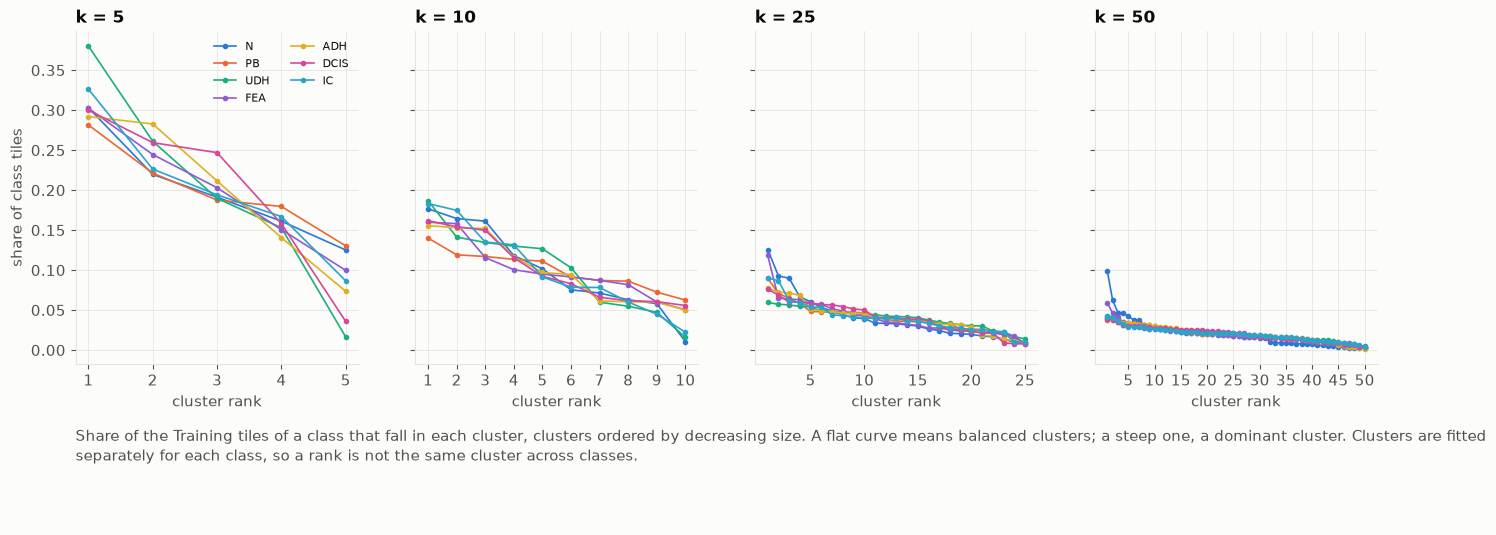

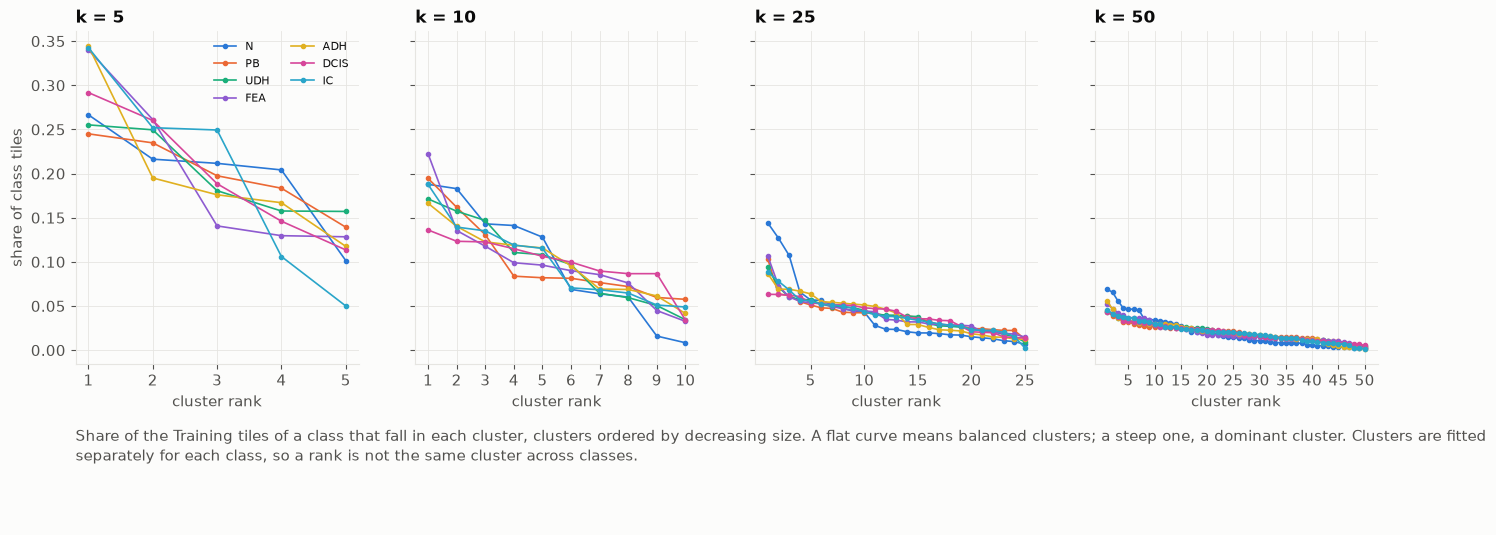

In [10]:
# STEP 1: Cluster-size table of every configuration
size_table = cluster_size_table(sizes)
display(size_table[size_table['pca_dim'] == DIAGNOSTIC_CONFIG[0]].round(3))

# STEP 2: Sorted cluster shares, one figure per dimension
for dim in PCA_DIMENSIONS:
    _ = plot_cluster_sizes(sizes, dim, classes)

### 8.3 Real and synthetic tile counts

The tile counts of the synthetic bags are compared with those of the real Training slides of the same class for the diagnostic configuration. Blending templates preserves the mean size but narrows its spread. The table of the largest weight of a single template shows how far one slide can dominate a bag.

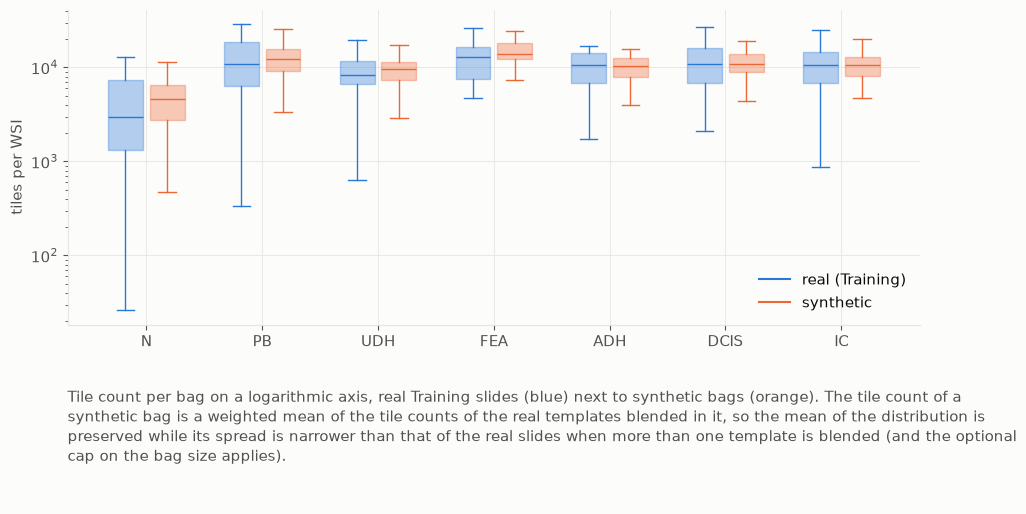

real                                                              \
      count     mean     std     min     25%      50%      75%      max   
N      27.0   5152.0  5393.0    26.0  1309.0   2939.0   7279.0  19418.0   
PB    120.0  12266.0  7217.0   337.0  6404.0  10868.0  18686.0  28956.0   
UDH    56.0  10005.0  6625.0   628.0  6587.0   8328.0  11759.0  35287.0   
FEA    24.0  14528.0  8063.0  4700.0  7446.0  12894.0  16550.0  30962.0   
ADH    28.0  10411.0  4881.0  1712.0  6871.0  10492.0  14382.0  17035.0   
DCIS   40.0  11714.0  6326.0  2083.0  6753.0  10978.0  15992.0  26726.0   
IC    100.0  11111.0  5770.0   875.0  6796.0  10514.0  14661.0  26885.0   

     synthetic                                                               
         count     mean     std     min      25%      50%      75%      max  
N        100.0   5050.0  2953.0   471.0   2757.0   4574.0   6550.0  14171.0  
PB       100.0  12597.0  4695.0  3326.0   9212.0  12284.0  15891.0  25880.0  
UDH      100.0   9808.0  3561.0  2897.0   7311.0   9649.0  11535.0  19590.0  
FEA      100.0  14933.0  4178.0  7367.0  12150.0  13788.0  18084.0  24701.0  
ADH      100.0  10269.0  2828.0  4032.0   7956.0  10428.0  12598.0  15606.0  
DCIS     100.0  11467.0  3649.0  4346.0   8981.0  10930.0  13834.0  19217.0  
IC       100.0  11050.0  3455.0  4686.0   8180.0  10674.0  13068.0  20166.0

,count,mean,std,min,25%,50%,75%,max
WSI label,,,,,,,,
N,100.0,0.46,0.11,0.26,0.38,0.44,0.53,0.77
PB,100.0,0.47,0.13,0.27,0.37,0.44,0.53,0.87
UDH,100.0,0.45,0.12,0.25,0.37,0.42,0.53,0.84
FEA,100.0,0.46,0.11,0.25,0.38,0.44,0.55,0.72
ADH,100.0,0.46,0.13,0.25,0.36,0.45,0.53,0.85
DCIS,100.0,0.46,0.12,0.26,0.37,0.45,0.53,0.87
IC,100.0,0.46,0.12,0.25,0.37,0.44,0.55,0.79


In [11]:
# STEP 1: Tile counts per class
res = results[DIAGNOSTIC_CONFIG]
_ = plot_tile_counts(train, res['wsis'], classes)
display(pd.concat({'real': train.groupby('label')['n_tiles'].describe(),
                   'synthetic': res['wsis'].groupby('WSI label')['n_tiles'].describe()}, axis=1).reindex(classes).round(0))
display(res['wsis'].groupby('WSI label')['max_template_weight'].describe().reindex(classes).round(2))

### 8.4 Real and synthetic cluster proportions

For the diagnostic configuration, the mean proportion per cluster of the real templates is compared with the synthetic bags (as drawn and after re-assignment). The standard deviation of the proportions over slides (real) and over bags (synthetic) is compared as well. The table gives the mean absolute difference over clusters for every configuration.

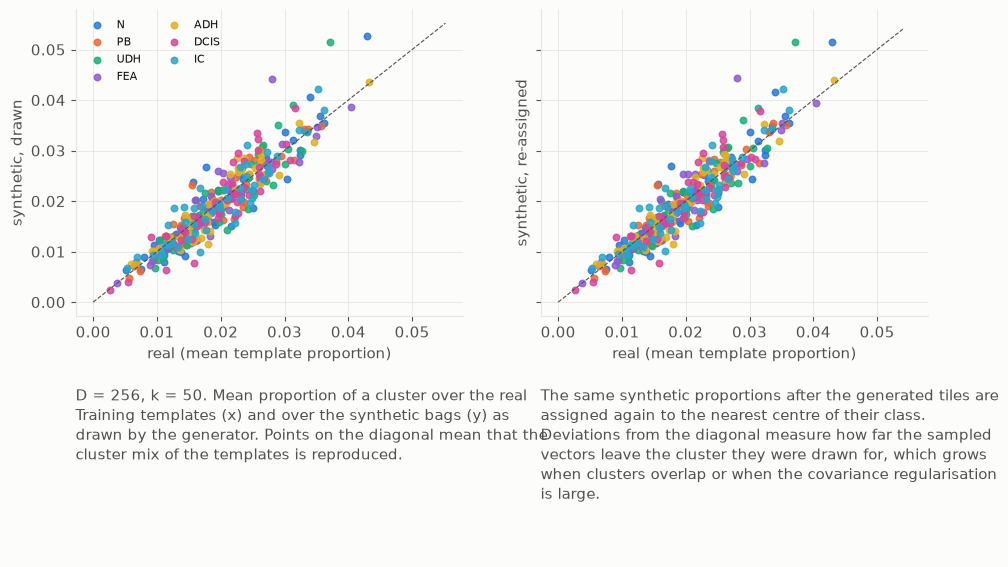

,pca_dim,k,drawn_vs_real,reassigned_vs_real
0,256,5,0.0094,0.0101
1,256,10,0.0076,0.0076
2,256,25,0.0041,0.0040
3,256,50,0.0023,0.0023
4,512,5,0.0106,0.0132
5,512,10,0.0072,0.0074
6,512,25,0.0037,0.0037
7,512,50,0.0024,0.0024


,real_std,drawn_std
label,,
N,0.0626,0.0339
PB,0.0617,0.0346
UDH,0.0581,0.0322
FEA,0.0460,0.0251
ADH,0.0533,0.0298
DCIS,0.0495,0.0273
IC,0.0627,0.0361


In [12]:
# STEP 1: Detailed comparison of the diagnostic configuration
comparison = composition_comparison(compositions[DIAGNOSTIC_CONFIG], res)
_ = plot_composition(comparison, classes, title=f'D = {DIAGNOSTIC_CONFIG[0]}, k = {DIAGNOSTIC_CONFIG[1]}.')

# STEP 2: Mean absolute difference per configuration
rows = []
for (dim, k), r in results.items():
    cmp_ = composition_comparison(compositions[(dim, k)], r)
    rows.append({'pca_dim': dim, 'k': k, 'drawn_vs_real': (cmp_['drawn'] - cmp_['real']).abs().mean(),
                 'reassigned_vs_real': (cmp_['reassigned'] - cmp_['real']).abs().mean()})
display(pd.DataFrame(rows).round(4))
display(comparison.groupby('label')[['real_std', 'drawn_std']].mean().reindex(classes).round(4))

### 8.5 Embedding statistics of real and synthetic tiles

For each class, a subsample of real Training tiles is compared with synthetic tiles coordinate by coordinate (mean and standard deviation) and by the mean vector norm; the first two principal components of the diagnostic configuration are plotted.

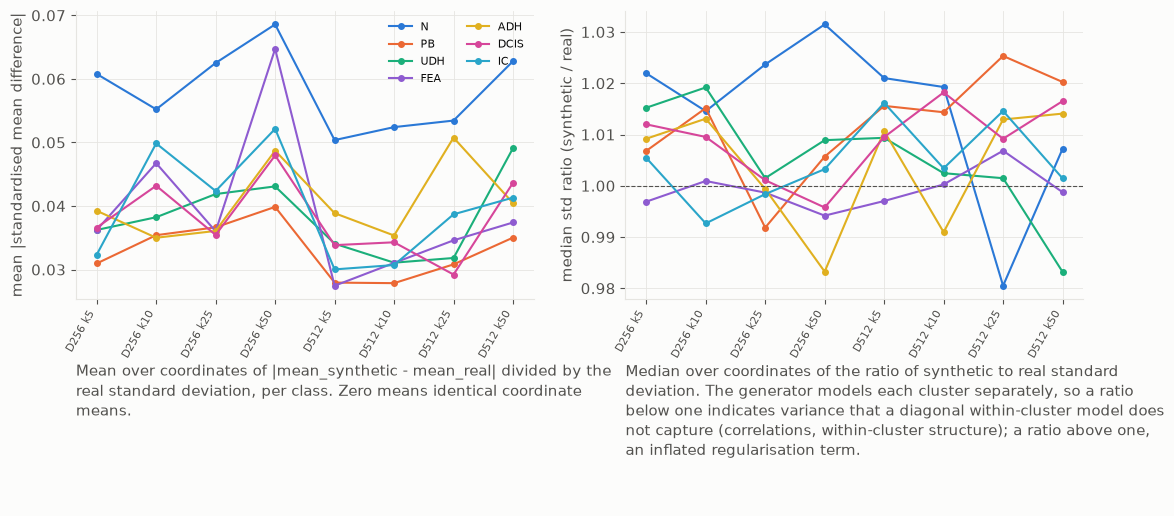

,label,mean_abs_smd,median_std_ratio,norm_real,norm_synthetic,pca_dim,k
21,N,0.069,1.031,12.881,13.122,256,50
22,PB,0.040,1.006,12.976,12.937,256,50
23,UDH,0.043,1.009,13.027,12.980,256,50
24,FEA,0.065,0.994,13.090,13.012,256,50
25,ADH,0.049,0.983,13.107,12.865,256,50
26,DCIS,0.048,0.996,13.056,12.795,256,50
27,IC,0.052,1.003,12.816,13.027,256,50


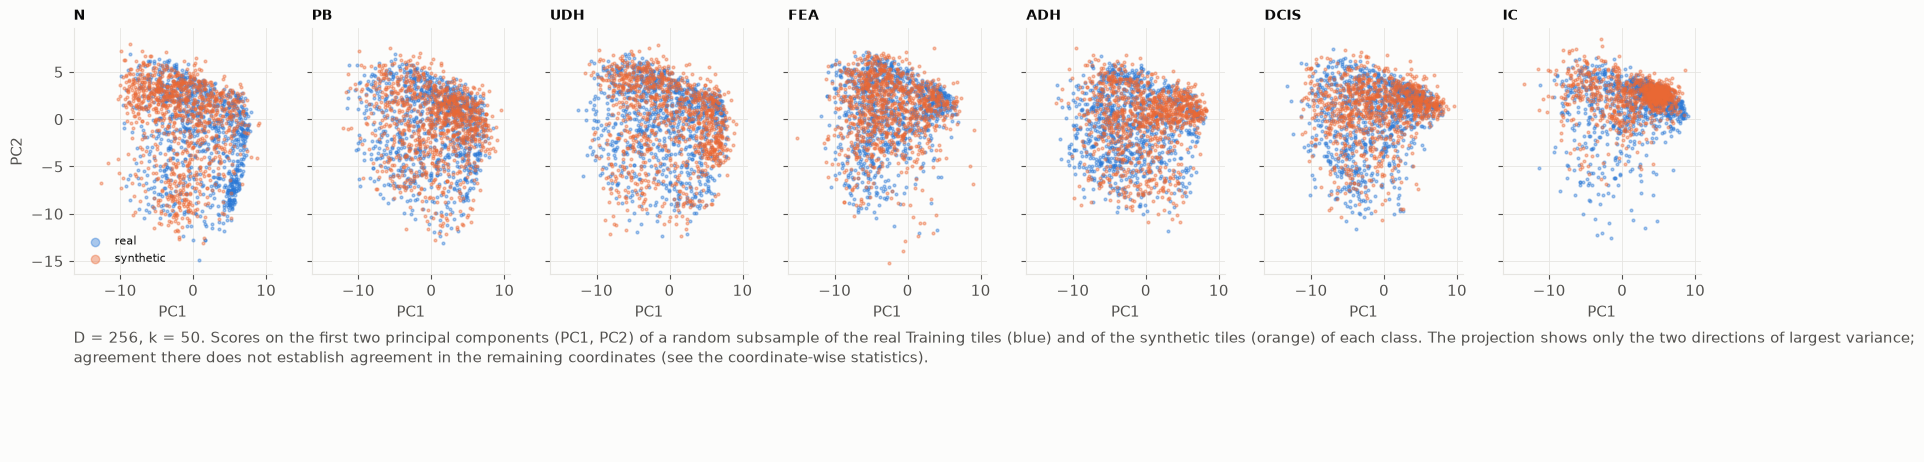

In [13]:
# STEP 1: Coordinate-wise statistics for every configuration
dist = pd.concat([r['distribution'].assign(pca_dim=dim, k=k) for (dim, k), r in results.items()], ignore_index=True)
_ = plot_distribution_stats(dist, classes)
display(dist[(dist['pca_dim'] == DIAGNOSTIC_CONFIG[0]) & (dist['k'] == DIAGNOSTIC_CONFIG[1])].round(3))

# STEP 2: Scores on the first two components
_ = plot_pc_scatter(res['scatter'], classes, title=f'D = {DIAGNOSTIC_CONFIG[0]}, k = {DIAGNOSTIC_CONFIG[1]}.')

## 9. Saving and reproducibility metadata

The bags were written in section 7. For each configuration, `metadata.json` (dimension, *k*, method, seed, bags per class, clustering, covariance type and regularisation, sampling, source split and a hash of the source slides, time stamp, library versions), `cluster_models.pt` (centres, cluster sizes and Gaussian parameters) and `labels.csv` are stored next to them. The label sheet of all configurations, `labels/BRACS_synthetic.csv`, uses the columns of `BRACS.xlsx` plus the configuration and the tile counts. Existing files are not replaced unless `OVERWRITE` is set.

In [14]:
# STEP 1: Metadata, cluster models and per-configuration labels
if SAVE_SYNTHETIC_EMBEDDINGS:
    for key, r in results.items():
        save_configuration_metadata(r, clusters[key], generators[key], compositions[key], r['settings'], train['slide'].tolist())

    # STEP 2: Label sheet of all configurations
    sheet = write_synthetic_labels(list(results.values()), LABELS_SYNTHETIC_FILE, OVERWRITE)
    display(sheet.groupby(['method', 'pca_dim', 'k', 'WSI label']).size().unstack().loc[:, classes])
else:
    print('SAVE_SYNTHETIC_EMBEDDINGS is False: nothing was written.')

WSI label              N   PB  UDH  FEA  ADH  DCIS   IC
method   pca_dim k                                     
gaussian 256     5   100  100  100  100  100   100  100
                 10  100  100  100  100  100   100  100
                 25  100  100  100  100  100   100  100
                 50  100  100  100  100  100   100  100
         512     5   100  100  100  100  100   100  100
                 10  100  100  100  100  100   100  100
                 25  100  100  100  100  100   100  100
                 50  100  100  100  100  100   100  100

## 10. Validation checks

One file of every configuration is read back and compared with its label-sheet row: shape `(n_tiles, D)`, dtype, finite values, label, set and the absence of real identifiers; the number of files per folder is compared with the configuration. No bag may be made of a single template when `N_TEMPLATES_PER_WSI > 1`.

In [15]:
# STEP 1: Reload one file per configuration
if SAVE_SYNTHETIC_EMBEDDINGS:
    sheet = pd.read_csv(LABELS_SYNTHETIC_FILE)
    for (dim, k), r in results.items():
        folder = r['folder']
        files = sorted(folder.glob('SYN_*.pt'))
        assert len(files) == N_SYNTHETIC_WSIS_PER_CLASS * len(classes), (folder, len(files))
        row = sheet[(sheet['pca_dim'] == dim) & (sheet['k'] == k)].iloc[len(files) // 2]
        d = torch.load(folder / f"{row['WSI Filename']}.pt", weights_only=True)
        x = d['cls_features']
        assert x.shape == (row['n_tiles'], dim) and x.dtype == torch.float32 and torch.isfinite(x).all()
        assert d['label'] == row['WSI label'] and d['set'] == 'Synthetic' and d['patient'] == d['slide'] == row['WSI Filename']
        assert 'BRACS' not in d['slide']
        if N_TEMPLATES_PER_WSI > 1:
            assert (r['wsis']['max_template_weight'] < 1).all()
    print('All', len(results), 'configurations passed the checks.')

All 8 configurations passed the checks.


## 11. Interpretation

To be written after the run on the workstation: the cluster balance per class and *k*, the agreement of tile counts and cluster proportions with the real templates (and the narrower spread caused by blending), the coordinate-wise agreement of the embeddings (standardised mean difference, standard-deviation ratio) and the share of tiles that fall back into their generating cluster.